# Where does the profit go? Retail sales analysis and forecast

**Data:** 8,399 order lines from a Canadian office-supplies retailer, January 2009 to December 2012 (the classic *Superstore Sales* dataset).

**Business questions**

1. How are sales and profit developing, and what is the overall margin?
2. Which products, shipping methods and discount levels destroy margin?
3. How concentrated is revenue across regions and customers?
4. Can we forecast monthly sales well enough to plan with?

**Approach:** quality-check the raw export, model it as a star schema in SQL (DuckDB), analyse KPIs in pandas, then compare three forecasting approaches against simple baselines on a held-out year.

In [1]:
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)

BLUE, RED, GREY, LIGHT = "#2563eb", "#dc2626", "#6b7280", "#cbd5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10,
})
eur = mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if abs(x) >= 1e6 else f"{x/1e3:.0f}k")

## 1. Data quality checks

Before any analysis I check what the raw export actually contains: missing values, duplicates, date ranges and whether the IDs mean what they seem to mean.

In [2]:
raw = pd.read_csv(ROOT / "data/superstore_sales.csv")
raw["Order Date"] = pd.to_datetime(raw["Order Date"], format="%m/%d/%Y")
raw["Ship Date"] = pd.to_datetime(raw["Ship Date"], format="%m/%d/%Y")

print(f"Rows: {len(raw):,} | Columns: {raw.shape[1]}")
print(f"Order dates: {raw['Order Date'].min():%Y-%m-%d} to {raw['Order Date'].max():%Y-%m-%d}")
print(f"Duplicate rows: {raw.duplicated().sum()}")
print("\nMissing values:")
print(raw.isna().sum()[lambda s: s > 0])

Rows: 8,399 | Columns: 21
Order dates: 2009-01-01 to 2012-12-30
Duplicate rows: 0

Missing values:
Product Base Margin    63
dtype: int64


In [3]:
ship_days = (raw["Ship Date"] - raw["Order Date"]).dt.days
print("Days from order to shipment:")
print(ship_days.describe()[["mean", "50%", "max"]])
print(f"Order lines shipped after more than 14 days: {(ship_days > 14).sum()}")

combos = raw[["Customer Name", "Customer Segment", "Province"]].drop_duplicates()
print(f"\nDistinct customer names: {raw['Customer Name'].nunique()}")
print(f"Distinct name + segment + province combinations: {len(combos)}")

Days from order to shipment:
mean    2.03
50%     2.00
max    92.00
dtype: float64
Order lines shipped after more than 14 days: 14

Distinct customer names: 795
Distinct name + segment + province combinations: 1832


**What I found**

- No duplicate rows. Only `Product Base Margin` has gaps (63 rows), and I don't use that column.
- Shipping is usually same-day to two days, with a handful of long outliers. Not a problem for this analysis.
- **Customer name is not a reliable customer ID.** 795 names appear in 1,832 different segment/province combinations, so the same name turns up as a corporate client in Ontario and a home office in Quebec. In a real job I'd ask the data owner for the CRM customer ID. Here I treat name + segment + province as the customer key in the star schema, and use plain names only for the concentration analysis, where that's the more conservative choice.

## 2. Star schema in SQL

The raw export is one wide table. I split it into a fact table (one row per order line) and customer, product and date dimensions, the same shape I'd use as a Power BI semantic model. The SQL lives in [`sql/`](../sql).

In [4]:
con = duckdb.connect()
con.execute(f"SET file_search_path = '{ROOT}'")
con.execute((ROOT / "sql/01_star_schema.sql").read_text())

con.sql("""
    SELECT 'fact_order_line' AS table_name, count(*) AS rows FROM fact_order_line
    UNION ALL SELECT 'dim_customer', count(*) FROM dim_customer
    UNION ALL SELECT 'dim_product', count(*) FROM dim_product
    UNION ALL SELECT 'dim_date', count(*) FROM dim_date
""").df()

,table_name,rows
0,fact_order_line,8399
1,dim_customer,1832
2,dim_product,1264
3,dim_date,1461


In [5]:
df = con.sql("""
    SELECT f.*, c.customer_name, c.segment, c.region, p.category, p.sub_category
    FROM fact_order_line f
    JOIN dim_customer c USING (customer_key)
    JOIN dim_product  p USING (product_key)
""").df()
df["order_date"] = pd.to_datetime(df["order_date"])
assert len(df) == len(raw), "join lost or duplicated rows"

## 3. Headline KPIs

In [6]:
yearly = con.sql("""
    SELECT year(order_date) AS year,
           sum(sales) AS sales, sum(profit) AS profit,
           sum(profit) / sum(sales) AS margin,
           count(DISTINCT order_id) AS orders
    FROM fact_order_line GROUP BY 1 ORDER BY 1
""").df().set_index("year")
yearly["sales_yoy"] = yearly["sales"].pct_change()
yearly.style.format({"sales": "{:,.0f}", "profit": "{:,.0f}", "margin": "{:.1%}",
                     "orders": "{:,}", "sales_yoy": "{:+.1%}"}, na_rep="")

,sales,profit,margin,orders,sales_yoy
year,,,,,
2009,"4,209,139","434,539",10.3%,"1,394",
2010,"3,549,681","363,871",10.3%,"1,393",-15.7%
2011,"3,436,817","381,456",11.1%,"1,317",-3.2%
2012,"3,719,964","341,902",9.2%,"1,392",+8.2%


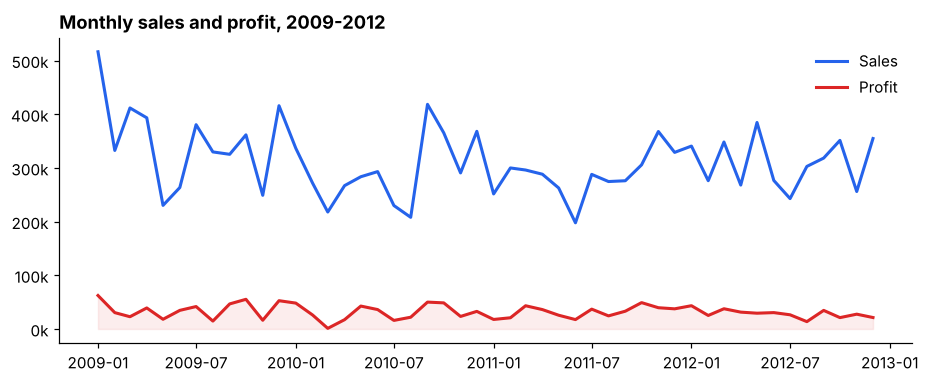

In [7]:
monthly = df.set_index("order_date")[["sales", "profit"]].resample("MS").sum()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(monthly.index, monthly["sales"], color=BLUE, lw=2, label="Sales")
ax.plot(monthly.index, monthly["profit"], color=RED, lw=2, label="Profit")
ax.fill_between(monthly.index, monthly["profit"], color=RED, alpha=0.08)
ax.yaxis.set_major_formatter(eur)
ax.set_title("Monthly sales and profit, 2009-2012")
ax.legend(frameon=False, loc="upper right")
fig.savefig(IMG / "01_monthly_trend.png")
plt.show()

Sales dropped about 16% from 2009 to 2010 and have been roughly flat since, at around 3.5M a year. The overall margin is only about 10%, and **2012 had the lowest margin of the four years (9.2%)** even though sales recovered. Monthly sales swing a lot (between roughly 200k and 500k) without an obvious seasonal pattern, which matters for the forecast later.

## 4. Where is margin lost?

In [8]:
cat = df.groupby("category").agg(sales=("sales", "sum"), profit=("profit", "sum"))
cat["margin"] = cat["profit"] / cat["sales"]
cat["share_of_sales"] = cat["sales"] / cat["sales"].sum()
cat["share_of_profit"] = cat["profit"] / cat["profit"].sum()
cat.sort_values("sales", ascending=False).style.format(
    {"sales": "{:,.0f}", "profit": "{:,.0f}", "margin": "{:.1%}",
     "share_of_sales": "{:.0%}", "share_of_profit": "{:.0%}"})

,sales,profit,margin,share_of_sales,share_of_profit
category,,,,,
Technology,"5,984,248","886,314",14.8%,40%,58%
Furniture,"5,178,591","117,433",2.3%,35%,8%
Office Supplies,"3,752,762","518,021",13.8%,25%,34%


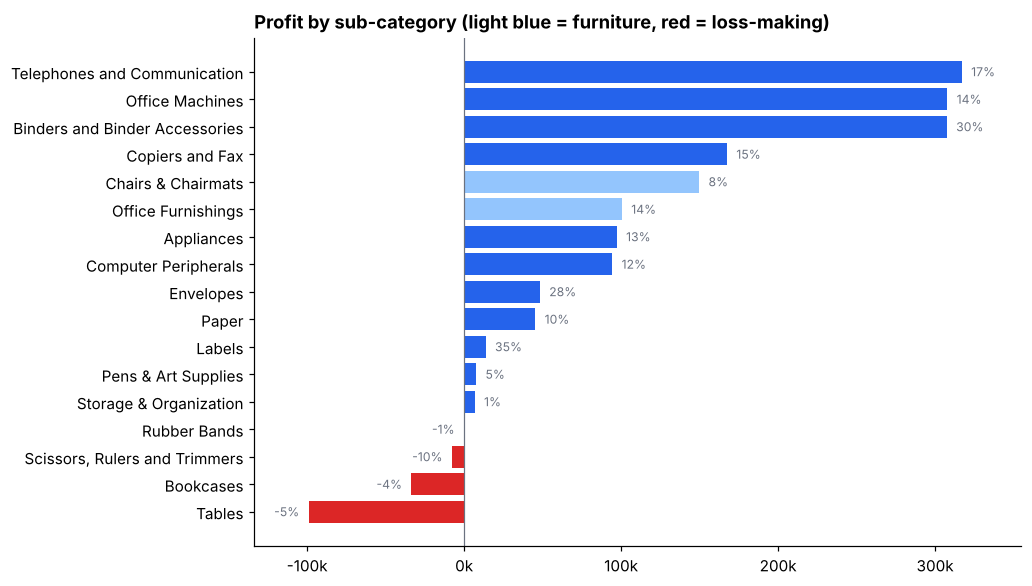

In [9]:
sub = df.groupby(["category", "sub_category"]).agg(sales=("sales", "sum"), profit=("profit", "sum"))
sub["margin"] = sub["profit"] / sub["sales"]
sub = sub.reset_index().sort_values("profit")

fig, ax = plt.subplots(figsize=(9, 6))
colors = [RED if p < 0 else (BLUE if c != "Furniture" else "#93c5fd") for p, c in zip(sub["profit"], sub["category"])]
ax.barh(sub["sub_category"], sub["profit"], color=colors)
ax.axvline(0, color=GREY, lw=0.8)
ax.xaxis.set_major_formatter(eur)
ax.set_title("Profit by sub-category (light blue = furniture, red = loss-making)")
ax.set_xlim(sub["profit"].min() * 1.35, sub["profit"].max() * 1.12)
for y, (p, m) in enumerate(zip(sub["profit"], sub["margin"])):
    ax.text(p + (6000 if p >= 0 else -6000), y, f"{m:.0%}", va="center",
            ha="left" if p >= 0 else "right", fontsize=8, color=GREY)
fig.savefig(IMG / "02_subcategory_profit.png")
plt.show()

**Furniture is 35% of sales but only 8% of profit (2.3% margin).** Tables and Bookcases lose money outright: together they lost about 133k on 2.7M of sales. Technology and Office Supplies both run at roughly 14-15% margin.

Next question: is that because furniture is discounted more, or because it's expensive to ship?

In [10]:
ship = df.groupby(["category", "ship_mode"]).agg(
    sales=("sales", "sum"), profit=("profit", "sum"), avg_shipping_cost=("shipping_cost", "mean"))
ship["margin"] = ship["profit"] / ship["sales"]
ship["share_of_total_sales"] = ship["sales"] / df["sales"].sum()
ship.style.format({"sales": "{:,.0f}", "profit": "{:,.0f}", "avg_shipping_cost": "{:.1f}",
                   "margin": "{:.1%}", "share_of_total_sales": "{:.0%}"})

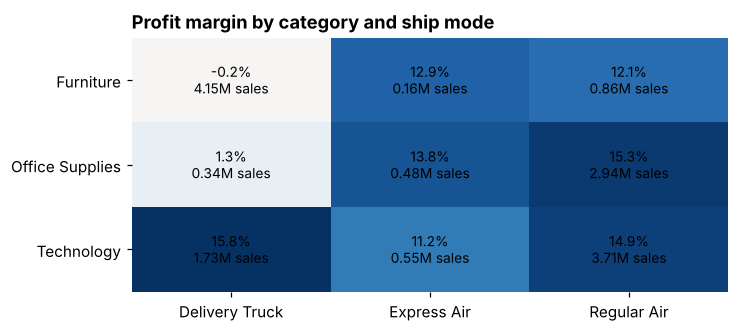

In [11]:
pivot = ship["margin"].unstack()
fig, ax = plt.subplots(figsize=(7, 3))
im = ax.imshow(pivot.values, cmap="RdBu", vmin=-0.16, vmax=0.16, aspect="auto")
ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        s = ship["sales"].unstack().iloc[i, j]
        ax.text(j, i, f"{pivot.iloc[i, j]:.1%}\n{s/1e6:.2f}M sales", ha="center", va="center", fontsize=9)
ax.set_title("Profit margin by category and ship mode")
ax.spines[:].set_visible(False)
fig.savefig(IMG / "03_shipmode_heatmap.png")
plt.show()

**This is the biggest single finding.** Furniture shipped by delivery truck is **4.15M of sales, 28% of all revenue, at a margin of essentially zero** (−0.2%). The same furniture shipped by air makes a 12-13% margin, but truck shipments carry an average shipping cost of about 49 per line versus 13 by air. Technology also often goes by truck and still makes 16%, so the truck itself isn't the problem. **Bulky furniture isn't priced to cover its freight.**

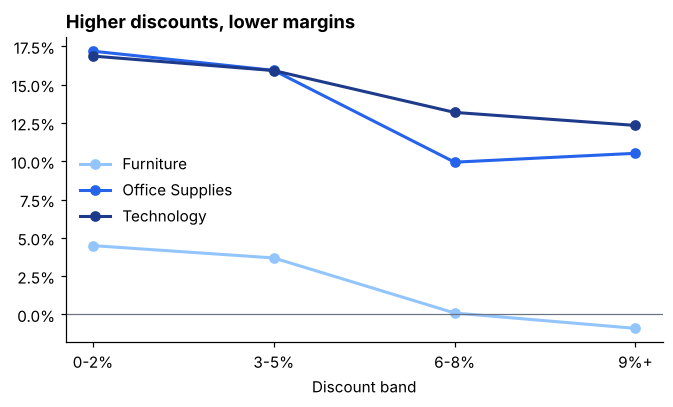

category,Furniture,Office Supplies,Technology
discount,,,
0-2%,4.5%,17.2%,16.9%
3-5%,3.7%,15.9%,15.9%
6-8%,0.1%,9.9%,13.2%
9%+,-0.9%,10.5%,12.3%


In [12]:
bands = pd.cut(df["discount"], [-0.01, 0.02, 0.05, 0.08, 1], labels=["0-2%", "3-5%", "6-8%", "9%+"])
disc = df.groupby([bands, "category"], observed=True).agg(sales=("sales", "sum"), profit=("profit", "sum"))
disc = (disc["profit"] / disc["sales"]).unstack()

fig, ax = plt.subplots(figsize=(7, 3.6))
for c, color in zip(disc.columns, ["#93c5fd", BLUE, "#1e3a8a"]):
    ax.plot(disc.index.astype(str), disc[c], marker="o", lw=2, color=color, label=c)
ax.axhline(0, color=GREY, lw=0.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Discount band")
ax.set_title("Higher discounts, lower margins")
ax.legend(frameon=False)
fig.savefig(IMG / "04_discount_margin.png")
plt.show()
disc.style.format("{:.1%}")

Margin drops steadily with discount in every category. Furniture falls to around zero at 6-8% discount and turns negative above that, but it's barely profitable even with no discount. **So discounts make the furniture problem worse, but they aren't its root cause.** Pricing and freight are.

## 5. Regions and customers

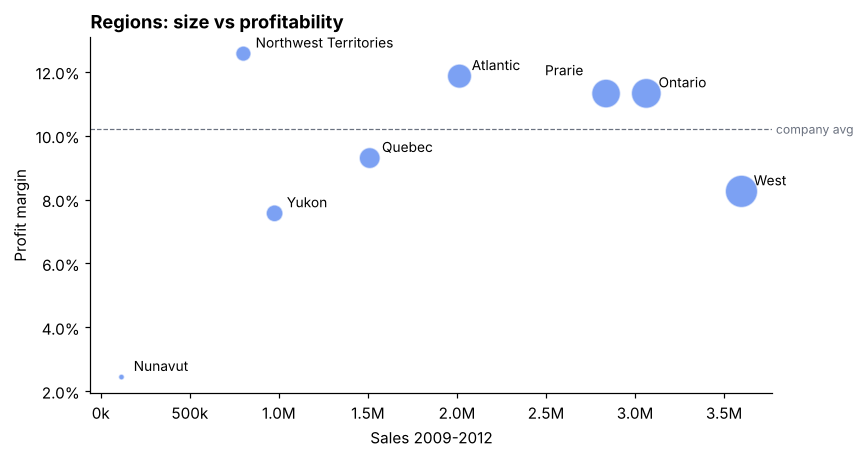

In [13]:
reg = df.groupby("region").agg(sales=("sales", "sum"), profit=("profit", "sum"))
reg["margin"] = reg["profit"] / reg["sales"]
avg_margin = df["profit"].sum() / df["sales"].sum()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(reg["sales"], reg["margin"], s=reg["sales"] / 8000, color=BLUE, alpha=0.6, edgecolor="white")
for name, r in reg.iterrows():
    offset = (-40, 12) if name == "Prarie" else (8, 4)
    ax.annotate(name, (r["sales"], r["margin"]), textcoords="offset points", xytext=offset, fontsize=9)
ax.axhline(avg_margin, color=GREY, ls="--", lw=0.8)
ax.text(ax.get_xlim()[1], avg_margin, " company avg", va="center", fontsize=8, color=GREY)
ax.xaxis.set_major_formatter(eur)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Sales 2009-2012")
ax.set_ylabel("Profit margin")
ax.set_title("Regions: size vs profitability")
fig.savefig(IMG / "05_regions.png")
plt.show()

In [14]:
rc = df.groupby(["region", "category"]).agg(sales=("sales", "sum"), profit=("profit", "sum"))
rc_margin = (rc["profit"] / rc["sales"]).unstack().loc[reg.sort_values("sales", ascending=False).index]
rc_margin.style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=-0.16, vmax=0.16)

category,Furniture,Office Supplies,Technology
region,,,
West,2.6%,14.6%,9.2%
Ontario,1.8%,16.5%,16.9%
Prarie,3.3%,11.6%,17.3%
Atlantic,2.2%,14.0%,18.9%
Quebec,-0.1%,12.2%,17.8%
Yukon,3.1%,9.5%,10.1%
Northwest Territories,2.6%,17.1%,18.7%
Nunavut,8.0%,-8.1%,7.3%


**West is the largest region but has a below-average margin (8.3%)**, and Nunavut barely breaks even. Ontario and the Prairies are both large and above average.

The margin table by region and category shows the West gap isn't about furniture, which is weak everywhere. It's **Technology: 9.2% margin in the West versus 17-19% in most other regions**. Discount levels are about the same across regions, so the next step would be to look at West technology pricing and deal terms with the regional sales team.

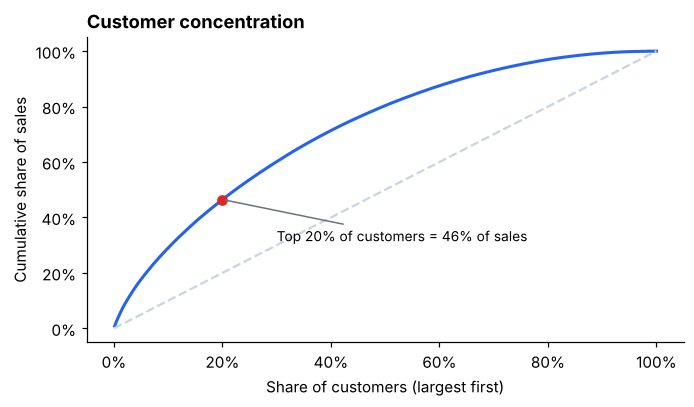

In [15]:
cust = df.groupby("customer_name")["sales"].sum().sort_values(ascending=False)
cum_share = cust.cumsum() / cust.sum()
pct_customers = np.arange(1, len(cust) + 1) / len(cust)
top20 = cum_share.iloc[int(len(cust) * 0.2) - 1]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(pct_customers, cum_share.values, color=BLUE, lw=2)
ax.plot([0, 1], [0, 1], color=LIGHT, ls="--")
ax.scatter([0.2], [top20], color=RED, zorder=3)
ax.annotate(f"Top 20% of customers = {top20:.0%} of sales", (0.2, top20), xytext=(0.3, top20 - 0.15),
            arrowprops=dict(arrowstyle="-", color=GREY), fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of customers (largest first)")
ax.set_ylabel("Cumulative share of sales")
ax.set_title("Customer concentration")
fig.savefig(IMG / "06_customer_pareto.png")
plt.show()

Revenue is concentrated but not dangerously so: the top 20% of customers bring in about 46% of sales, which is a softer curve than the usual 80/20 rule. Losing a single large account wouldn't be critical.

## 6. Forecasting monthly sales

**Setup:** train on 2009-2011 (36 months) and forecast all 12 months of 2012 without looking at them. Metric: MAPE (mean absolute percentage error).

Before fitting anything clever I check two baselines, since a model is only useful if it beats them:

- **Seasonal naive:** each 2012 month equals the same month in 2011.
- **Mean of last 12 months:** a flat line at the 2011 average.

In [16]:
series = monthly["sales"]
train, test = series[:"2011"], series["2012"]

def mape(actual, forecast):
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(forecast)) / np.asarray(actual)) * 100)

forecasts = {
    "Seasonal naive": train[-12:].values,
    "Mean of last 12 months": np.repeat(train[-12:].mean(), 12),
}

lag12 = acf(train, nlags=12)[12]
print(f"Autocorrelation at lag 12 (yearly seasonality): {lag12:.2f}")

Autocorrelation at lag 12 (yearly seasonality): 0.03


The autocorrelation at lag 12 is low, which confirms what the trend chart suggested: **there is little stable yearly seasonality** to exploit. That's a warning sign for seasonal models.

**SARIMA:** I pick the order by AIC over a small grid, keeping the seasonal differencing fixed so the AIC values are comparable.

In [17]:
import itertools

best = None
for p, q, P, Q in itertools.product([0, 1, 2], [0, 1], [0, 1], [0, 1]):
    try:
        fit = SARIMAX(train, order=(p, 0, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
    except Exception:
        continue
    if best is None or fit.aic < best[0]:
        best = (fit.aic, (p, 0, q), (P, 1, Q, 12), fit)

aic, order, seasonal_order, sarima = best
print(f"Selected SARIMA{order}x{seasonal_order}, AIC = {aic:.1f}")
forecasts["SARIMA"] = sarima.forecast(12).values

Selected SARIMA(1, 0, 1)x(0, 1, 1, 12), AIC = 611.5


**XGBoost:** a gradient-boosted tree model on lag features (the last 3 months, the same month last year, rolling means and the calendar month). It forecasts recursively: each prediction is fed back in as a lag for the next month, so it never sees 2012 actuals. Trees are kept shallow because there are only 24 training rows after building the lags. I average five random seeds so the result doesn't depend on one lucky run.

In [18]:
def make_features(history, month):
    h = np.asarray(history)
    return [h[-1], h[-2], h[-3], h[-12], h[-3:].mean(), h[-12:].mean(), month]

X = [make_features(train.values[:i], train.index[i].month) for i in range(12, len(train))]
y = train.values[12:]

runs = []
for seed in range(5):
    model = XGBRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                         subsample=0.8, random_state=seed).fit(np.array(X), y)
    history, preds = list(train.values), []
    for date in test.index:
        pred = float(model.predict(np.array([make_features(history, date.month)]))[0])
        preds.append(pred)
        history.append(pred)
    runs.append(preds)

forecasts["XGBoost (lag features)"] = np.mean(runs, axis=0)
seed_mapes = [mape(test, r) for r in runs]
print(f"XGBoost MAPE across seeds: {min(seed_mapes):.1f}% to {max(seed_mapes):.1f}%")

XGBoost MAPE across seeds: 11.0% to 11.7%


In [19]:
results = pd.DataFrame({
    "MAPE 2012 (%)": {name: mape(test, f) for name, f in forecasts.items()},
    "Total 2012 forecast": {name: f.sum() for name, f in forecasts.items()},
})
results["Error on yearly total (%)"] = (results["Total 2012 forecast"] / test.sum() - 1) * 100
results = results.sort_values("MAPE 2012 (%)")
print(f"Actual 2012 sales: {test.sum():,.0f}")
results.style.format({"MAPE 2012 (%)": "{:.1f}", "Total 2012 forecast": "{:,.0f}",
                      "Error on yearly total (%)": "{:+.1f}"})

Actual 2012 sales: 3,719,964


,MAPE 2012 (%),Total 2012 forecast,Error on yearly total (%)
XGBoost (lag features),11.2,"3,584,800",-3.6
Mean of last 12 months,13.0,"3,436,817",-7.6
SARIMA,16.9,"3,463,486",-6.9
Seasonal naive,18.5,"3,436,817",-7.6


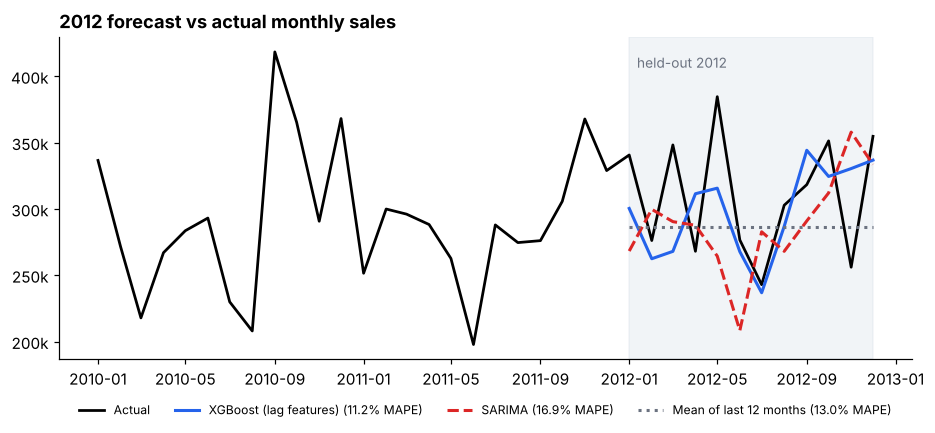

In [20]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(series["2010":].index, series["2010":].values, color="black", lw=1.8, label="Actual")
styles = {"XGBoost (lag features)": (BLUE, "-"), "SARIMA": (RED, "--"), "Mean of last 12 months": (GREY, ":")}
for name, (color, ls) in styles.items():
    ax.plot(test.index, forecasts[name], color=color, ls=ls, lw=2,
            label=f"{name} ({results.loc[name, 'MAPE 2012 (%)']:.1f}% MAPE)")
ax.axvspan(test.index[0], test.index[-1], color=LIGHT, alpha=0.25)
ax.text(test.index[0], ax.get_ylim()[1] * 0.97, "  held-out 2012", va="top", fontsize=9, color=GREY)
ax.yaxis.set_major_formatter(eur)
ax.set_title("2012 forecast vs actual monthly sales")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
fig.savefig(IMG / "07_forecast.png")
plt.show()

**Result:** XGBoost on lag features had the lowest monthly error, about 11% MAPE against 13% for the flat baseline. SARIMA did *worse* than the flat baseline because it chased a seasonal pattern that isn't really there.

**How I'd use this in practice:**

- At about 11% monthly error, the model is good for **quarterly and yearly planning**. Its full-year total came within 4% of actual 2012 sales.
- It's not precise enough for month-by-month targets. With only 36 months of history and no external drivers (promotions, pipeline, number of sales reps), I'd say so plainly to stakeholders rather than oversell it.
- The next improvement would be adding pipeline data from the CRM, the same approach I used for forecast reporting at Capgemini.

## 7. Recommendations

In [21]:
truck_furn = df[(df["category"] == "Furniture") & (df["ship_mode"] == "Delivery Truck")]
total_profit = df["profit"].sum()
per_point = truck_furn["sales"].sum() * 0.01

print(f"Furniture by truck: {truck_furn['sales'].sum():,.0f} sales, {truck_furn['profit'].sum():,.0f} profit")
print(f"Each +1 point of margin on these orders adds {per_point:,.0f} profit "
      f"(+{per_point / total_profit:.1%} of total company profit)")
print(f"Reaching 8% margin on them would add about {per_point * 8.2:,.0f} "
      f"(+{per_point * 8.2 / total_profit:.0%} of total profit)")

Furniture by truck: 4,154,946 sales, -8,175 profit
Each +1 point of margin on these orders adds 41,549 profit (+2.7% of total company profit)
Reaching 8% margin on them would add about 340,706 (+22% of total profit)


1. **Price freight into bulky furniture.** Furniture shipped by truck is 28% of revenue at zero margin. Adding a freight surcharge or minimum order value for truck delivery, enough to reach even an 8% margin, would add roughly a fifth to total company profit. That's the largest lever in the data.
2. **Review Tables and Bookcases pricing.** They lose money at every discount level, so this is a list-price problem, not a discount problem.
3. **Require approval for furniture discounts above 5%.** Margin is zero or negative beyond that.
4. **Investigate Technology margins in the West.** It's the largest region, and its technology margin is half what other regions achieve.
5. **Use the forecast for quarterly planning, not monthly targets**, and add CRM pipeline data as the next step.

**Limitations:** this is a public sample dataset, so currency, cost allocation and how `Profit` is calculated aren't documented. Customer names aren't unique IDs (see section 1). And the analysis shows correlation: before changing prices I'd test the freight surcharge on one region first.